#### Análisis y Procesamiento de Señales

# TS2: Modelizando un ADC
#### Juan Martucci

# Análisis Y Resultados

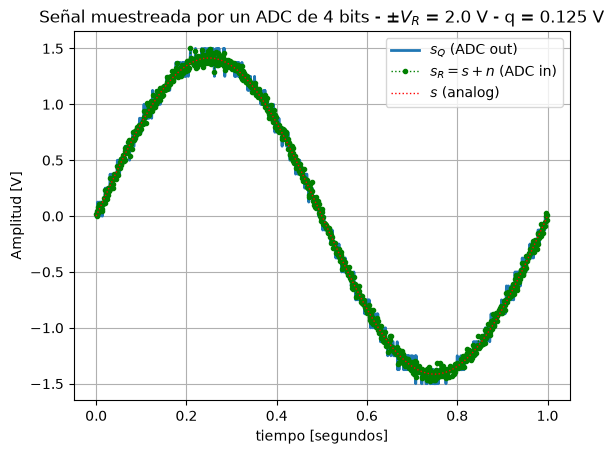

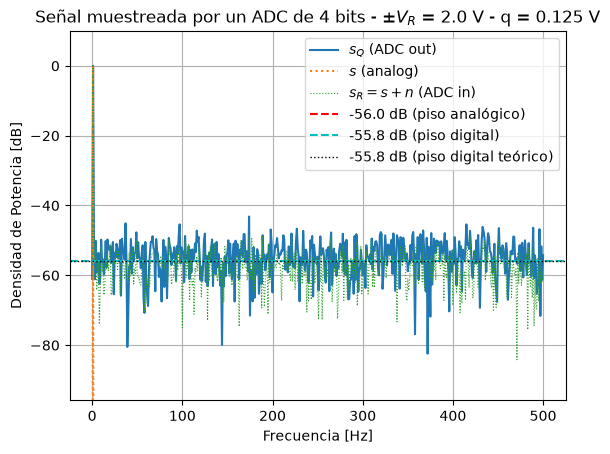

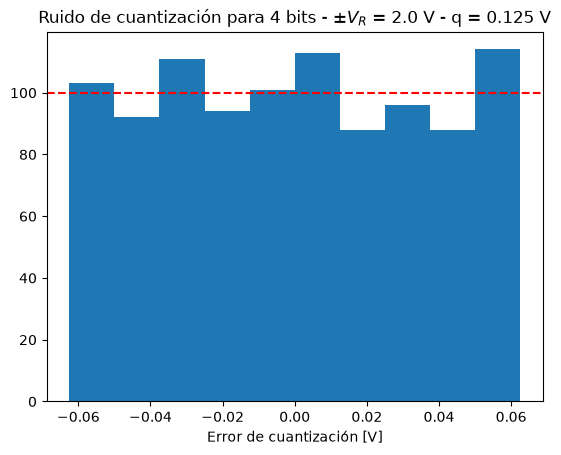

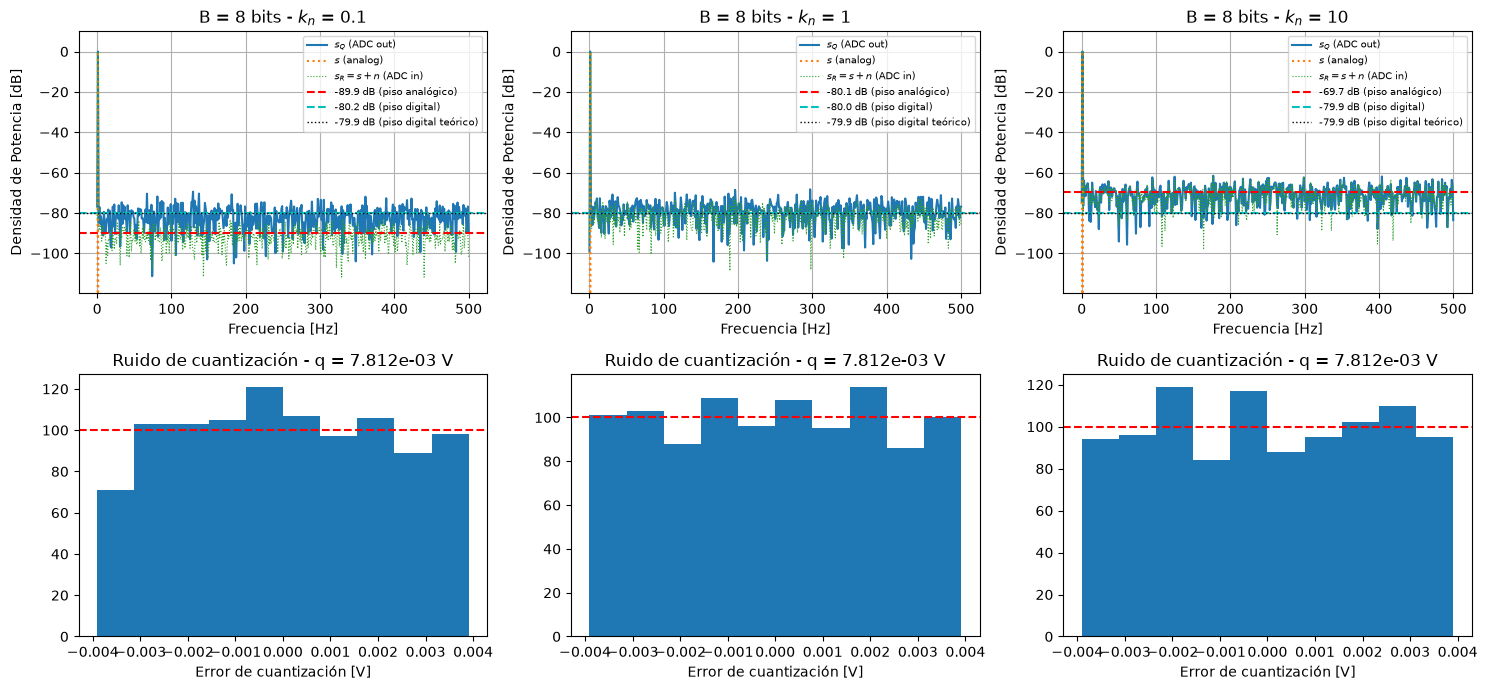

  B     kn        q [V]   SNR teo [dB]   SNR med [dB]
  4   0.10    1.250e-01          28.44          28.68
  4   1.00    1.250e-01          25.84          25.82
  4  10.00    1.250e-01          18.44          18.19
  8   0.10    7.812e-03          52.52          52.90
  8   1.00    7.812e-03          49.93          49.99
  8  10.00    7.812e-03          42.52          42.75
 16   0.10    3.052e-05         100.69         100.71
 16   1.00    3.052e-05          98.09          97.84
 16  10.00    3.052e-05          90.69          91.04


In [1]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

# Parámetros generales

np.random.seed(42)

N  = 1000
fs = 1000
VF = 2

df = fs/N
f0 = df

frecs = np.arange(N)*df
bfrec = frecs <= fs/2


def mi_funcion_sen(Vmax=1, dc=0, ff=1, ph=0, nn=N, fs=fs):
    deltaf = fs/nn
    Ts = 1/(nn*deltaf)
    tt = np.arange(0, stop=nn*Ts, step=Ts)
    xx = Vmax*np.sin(2*np.pi*ff*tt + ph) + dc
    return tt, xx


def mi_adc(B, kn):
    q  = VF/2**B
    Pq = q**2/12
    Pn = kn*Pq

    tt, s = mi_funcion_sen(Vmax=np.sqrt(2), ff=f0)
    n  = np.random.normal(0, np.sqrt(Pn), N)
    sr = s + n
    sq = np.clip(np.round(sr/q)*q, -VF, VF)
    nq = sq - sr

    return tt, s, n, sr, sq, nq, q


def psd_db(xx):
    return 10*np.log10(2*np.abs(np.fft.fft(xx)/N)**2 + 1e-30)


def plot_psd(ax, s, n, sr, sq, nq, q):
    piso_analog  = 10*np.log10(2*np.mean(n**2)/N)
    piso_digital = 10*np.log10(2*np.mean(nq**2)/N)
    piso_teorico = 10*np.log10(2*(q**2/12)/N)

    ax.plot(frecs[bfrec], psd_db(sq)[bfrec], lw=1.5, label='$s_Q$ (ADC out)')
    ax.plot(frecs[bfrec], psd_db(s)[bfrec], ':', label='$s$ (analog)')
    ax.plot(frecs[bfrec], psd_db(sr)[bfrec], ':', lw=0.8, label='$s_R = s+n$ (ADC in)')
    ax.axhline(piso_analog, color='r', ls='--',
               label='{:5.1f} dB (piso analógico)'.format(piso_analog))
    ax.axhline(piso_digital, color='c', ls='--',
               label='{:5.1f} dB (piso digital)'.format(piso_digital))
    ax.axhline(piso_teorico, color='k', ls=':', lw=1,
               label='{:5.1f} dB (piso digital teórico)'.format(piso_teorico))
    ax.set_ylim([10*np.log10(2*(q**2/12)/N) - 40, 10])
    ax.set_xlabel('Frecuencia [Hz]')
    ax.set_ylabel('Densidad de Potencia [dB]')
    ax.grid(True)


def plot_hist(ax, nq, q):
    ax.hist(nq, bins=10, range=(-q/2, q/2))
    ax.axhline(N/10, color='r', ls='--')
    ax.set_xlabel('Error de cuantización [V]')


# a) B = 4 bits, kn = 1

B, kn = 4, 1
tt, s, n, sr, sq, nq, q = mi_adc(B, kn)

titulo = 'Señal muestreada por un ADC de {:d} bits - $\\pm V_R$ = {:3.1f} V - q = {:5.3f} V'.format(B, VF, q)

plt.figure(1)
plt.plot(tt, sq, lw=2, label='$s_Q$ (ADC out)')
plt.plot(tt, sr, 'g.', ls=':', lw=1, label='$s_R = s+n$ (ADC in)')
plt.plot(tt, s, 'r', ls=':', lw=1, label='$s$ (analog)')
plt.title(titulo)
plt.xlabel('tiempo [segundos]')
plt.ylabel('Amplitud [V]')
plt.legend()
plt.grid(True)

plt.figure(2)
plot_psd(plt.gca(), s, n, sr, sq, nq, q)
plt.title(titulo)
plt.legend()

plt.figure(3)
plot_hist(plt.gca(), nq, q)
plt.title('Ruido de cuantización para {:d} bits - $\\pm V_R$ = {:3.1f} V - q = {:5.3f} V'.format(B, VF, q))

plt.show()


# b) B = 8 bits, kn = {1/10, 1, 10}

B   = 8
kns = [1/10, 1, 10]

fig, axs = plt.subplots(2, 3, figsize=(15, 7))

for jj, kn in enumerate(kns):

    tt, s, n, sr, sq, nq, q = mi_adc(B, kn)

    plot_psd(axs[0, jj], s, n, sr, sq, nq, q)
    axs[0, jj].set_title('B = {:d} bits - $k_n$ = {:g}'.format(B, kn))
    axs[0, jj].legend(fontsize=7)

    plot_hist(axs[1, jj], nq, q)
    axs[1, jj].set_title('Ruido de cuantización - q = {:5.3e} V'.format(q))

plt.tight_layout()
plt.show()


print('{:>3} {:>6} {:>12} {:>14} {:>14}'.format('B', 'kn', 'q [V]', 'SNR teo [dB]', 'SNR med [dB]'))

for B in [4, 8, 16]:
    for kn in [1/10, 1, 10]:

        tt, s, n, sr, sq, nq, q = mi_adc(B, kn)

        SNR_med = 10*np.log10(np.mean(s**2) / np.mean((sq - s)**2))
        SNR_teo = 10*np.log10(3*2**(2*B) / (1 + kn))

        print('{:3d} {:6.2f} {:12.3e} {:14.2f} {:14.2f}'.format(B, kn, q, SNR_teo, SNR_med))

## Conclusión

**a) B = 4 bits, kn = 1.**
El error de cuantización se reparte de forma aproximadamente uniforme en
[-q/2, q/2]. El histograma es plano dentro de la dispersión esperable para
1000 muestras en 10 bins (del orden de +/-10 cuentas por bin), y el piso
digital medido, -55.8 dB, coincide con el teórico 10*log10(2*Pq/N) = -55.8 dB.
Como kn = 1 implica Pn = Pq, el piso analógico queda superpuesto al digital
(-56.0 dB medido).
Conviene notar que en la figura de referencia del enunciado esos dos pisos
aparecen separados unos 10 dB (-46.2 y -55.8 dB); esa separación es la que
obtengo con kn = 10, no con kn = 1.

**b) B = 8 bits, kn = {1/10, 1, 10}.**
El piso digital se mantiene en aproximidamente -80.0 dB en los tres casos, mientras que el
analógico se corre 10*log10(kn) respecto de aquel. Con kn = 1/10 el ruido de
entrada queda por debajo del de cuantización y es el ADC el que limita; con
kn = 10 domina la interferencia y agregar resolución no aportaría nada.
Comparado con a), pasar de 4 a 8 bits divide q por 16 y baja el piso digital
24 dB, es decir 6 dB por bit.

Con kn = 1/10 el histograma es visiblemente menos plano que en los otros dos
casos. Con poco ruido a la entrada el error de cuantización queda correlacionado
con la señal y deja de comportarse como ruido blanco; el ruido aditivo cumple
acá el papel de dither.

El SNR no se corre esos mismos 10 dB porque lo que pesa es el ruido total. De
kn = 1 a kn = 10 la potencia de ruido pasa de 2*Pq a 11*Pq, o sea 7.4 dB, y de
kn = 1 a kn = 1/10 mejora 2.6 dB. La tabla lo confirma: para B = 8 el SNR medido
da 52.90, 49.99 y 42.75.

#### Bonus: relación entre B y el SNR

Con Ps = 1, q = VF/2^B y ruido total (1+kn)*Pq resulta

    SNR = 3*2^(2B)/(1+kn)        SNR|dB = 6.02*B + 4.77 - 10*log10(1+kn)

es decir 6 dB de mejora por cada bit agregado. Holton llega a 6.02*B + 1.76 dB.
Los 3 dB de diferencia en el término constante vienen de las convenciones: acá
la senoidal no es de fondo de escala (Ps = 1 en lugar de VF^2/2, -3 dB) y el q
del enunciado es la mitad del q de libro, 2*VF/2^B (+6 dB). En la tabla el SNR
medido sigue esta expresión con un error menor a 0.4 dB en las nueve
combinaciones de B y kn.